# EDA: r/tennis discussion and match results

Milestone 1 (Nov 22). Three parts:

1. **Volume**: posts and comments over time, busiest days, deleted content
2. **Player mentions**: who gets talked about, Big 3 share over time, men's vs women's coverage
3. **Thread-to-match linking**: match threads joined to Sackmann match records, link rate, first look at attention

Run on EC2 from the repo root:

```bash
EDA_MODE=sample jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 code/eda/04_eda.ipynb
EDA_MODE=full   jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 code/eda/04_eda.ipynb
```

`sample` uses the 1% comment sample (counts are scaled ×100 as estimates) and writes outputs to `~/data/eda_sample/`.
`full` uses every comment and writes CSVs and figures into `website-source/` for the EDA page.
Thread linking always uses all 96k threads, since that table is small.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())
sys.path.insert(0, str(REPO / "code" / "common"))
from players import BIG3, PLAYERS, pattern

MODE = os.environ.get("EDA_MODE", "sample")
assert MODE in ("sample", "full"), MODE
DATA = Path.home() / "data"
PARQUET = DATA / "parquet" / "subreddit-tennis"
MATCHES = DATA / "matches"
YEARS = (2012, 2018)
SCALE = 100 if MODE == "sample" else 1  # sample counts x100 ~ full counts

if MODE == "full":
    OUT_DATA = REPO / "website-source" / "data" / "eda"
    OUT_IMG = REPO / "website-source" / "images" / "eda"
else:
    OUT_DATA = OUT_IMG = DATA / "eda_sample"
OUT_DATA.mkdir(parents=True, exist_ok=True)
OUT_IMG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.figsize": (9, 4), "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
summary = {"mode": MODE}

ACCENTS = "áàâäãåāăąćčçďđéèêëēėęěíìîïīįłľĺńňñóòôöõøőřśšşșťţțúùûüůűūýÿžźżğ"
PLAIN   = "aaaaaaaaacccddeeeeeeeeiiiiiilllnnnooooooorsssstttuuuuuuuyyzzzg"

def plain_lower(c):
    # Lowercase and strip accents, so "Čilić" matches "cilic".
    return F.translate(F.lower(c), ACCENTS, PLAIN)

def save_csv(df, name):
    df.to_csv(OUT_DATA / f"{name}.csv", index=False)

def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(OUT_IMG / f"{name}.png", dpi=150, bbox_inches="tight")

print("mode:", MODE, "| outputs:", OUT_DATA)

mode: full | outputs: /home/ubuntu/tennis-reddit-analysis/website-source/data/eda


In [2]:
spark = (
    SparkSession.builder.appName(f"eda-{MODE}")
    .master("local[2]")
    .config("spark.driver.memory", "5g")
    .config("spark.sql.shuffle.partitions", "16")
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")

utts = (
    spark.read.parquet(str(PARQUET / ("comments" if MODE == "full" else "comments_sample")))
    .filter(F.col("year").between(*YEARS))
    .withColumn("is_deleted", F.col("text").isin("[deleted]", "[removed]") | F.col("text").isNull())
    .cache()
)
threads = (
    spark.read.parquet(str(PARQUET / "threads"))
    .withColumn("thread_date", F.to_date(F.from_unixtime(F.col("timestamp").cast("long"))))
    .withColumn("year", F.year("thread_date"))
    .withColumn("num_comments", F.col("num_comments").cast("int"))
    .filter(F.col("year").between(*YEARS))
    .cache()
)
print("utterances:", utts.count(), "| threads:", threads.count())

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/17 23:06:12 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


26/11/17 23:06:26 WARN GarbageCollectionMetrics: To enable non-built-in garbage collector(s) List(G1 Concurrent GC), users should configure it(them) to spark.eventLog.gcMetrics.youngGenerationGarbageCollectors or spark.eventLog.gcMetrics.oldGenerationGarbageCollectors


utterances: 1904293 | threads: 94625


## 1. Volume

In [3]:
by_year = (
    utts.groupBy("year")
    .agg(
        F.sum(F.col("is_post").cast("int")).alias("posts"),
        F.sum((~F.col("is_post")).cast("int")).alias("comments"),
        F.countDistinct("author").alias("authors"),
        F.avg(F.col("is_deleted").cast("int")).alias("share_deleted"),
    )
    .orderBy("year")
    .toPandas()
)
for c in ["posts", "comments"]:
    by_year[c] = by_year[c] * SCALE
by_year["share_deleted"] = by_year["share_deleted"].round(3)
save_csv(by_year, "volume_by_year")
summary["share_deleted"] = float(utts.select(F.avg(F.col("is_deleted").cast("int"))).first()[0])
by_year

,year,posts,comments,authors,share_deleted
0,2012,3853,27842,3557,0.071
1,2013,7249,64226,5901,0.055
2,2014,9278,100792,7542,0.046
3,2015,13597,192555,11742,0.045
4,2016,16434,270201,13562,0.053
5,2017,21260,542629,19554,0.054
6,2018,22954,611423,24714,0.058


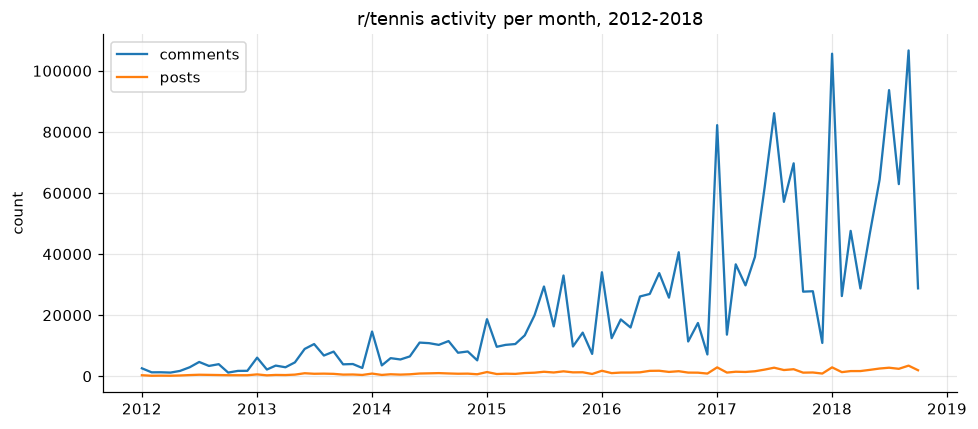

In [4]:
monthly = (
    utts.groupBy("year", "month")
    .agg(
        F.sum(F.col("is_post").cast("int")).alias("posts"),
        F.sum((~F.col("is_post")).cast("int")).alias("comments"),
    )
    .toPandas()
)
monthly["date"] = pd.to_datetime(dict(year=monthly.year, month=monthly.month, day=1))
monthly = monthly.sort_values("date")
monthly[["posts", "comments"]] *= SCALE
save_csv(monthly, "volume_monthly")

fig, ax = plt.subplots()
ax.plot(monthly.date, monthly.comments, label="comments")
ax.plot(monthly.date, monthly.posts, label="posts")
ax.set_title("r/tennis activity per month, 2012-2018" + (" (estimated from 1% sample)" if MODE == "sample" else ""))
ax.set_ylabel("count")
ax.legend()
save_fig(fig, "volume_monthly")

In [5]:
# Busiest days: expected to line up with Grand Slam finals.
top_days = (
    utts.filter(~F.col("is_post")).groupBy("date").count()
    .orderBy(F.desc("count")).limit(20).toPandas()
)
top_days["count"] *= SCALE
save_csv(top_days, "top_days")
top_days

,date,count
0,2018-07-13,19171
1,2017-01-29,18901
2,2018-09-09,15272
3,2018-09-08,12173
4,2018-09-05,11885
5,2018-07-11,11728
6,2018-01-28,11599
7,2017-07-10,11424
8,2018-07-14,10270
9,2018-09-04,8989


## 2. Player mentions

A comment mentions a player if it matches any of their names or nicknames
(`code/common/players.py`, case-insensitive, whole words). A comment can mention several players.

29.2% of comments mention at least one listed player
mention share by tour: {'ATP': 0.869, 'WTA': 0.131}


,player,count,tour
12,Federer,171646,ATP
22,Nadal,151177,ATP
3,Djokovic,119022,ATP
16,Andy Murray,55597,ATP
17,Wawrinka,37591,ATP
23,Serena Williams,31256,WTA
11,Del Potro,28644,ATP
24,Thiem,19823,ATP
1,Kyrgios,19328,ATP
4,Nishikori,17658,ATP


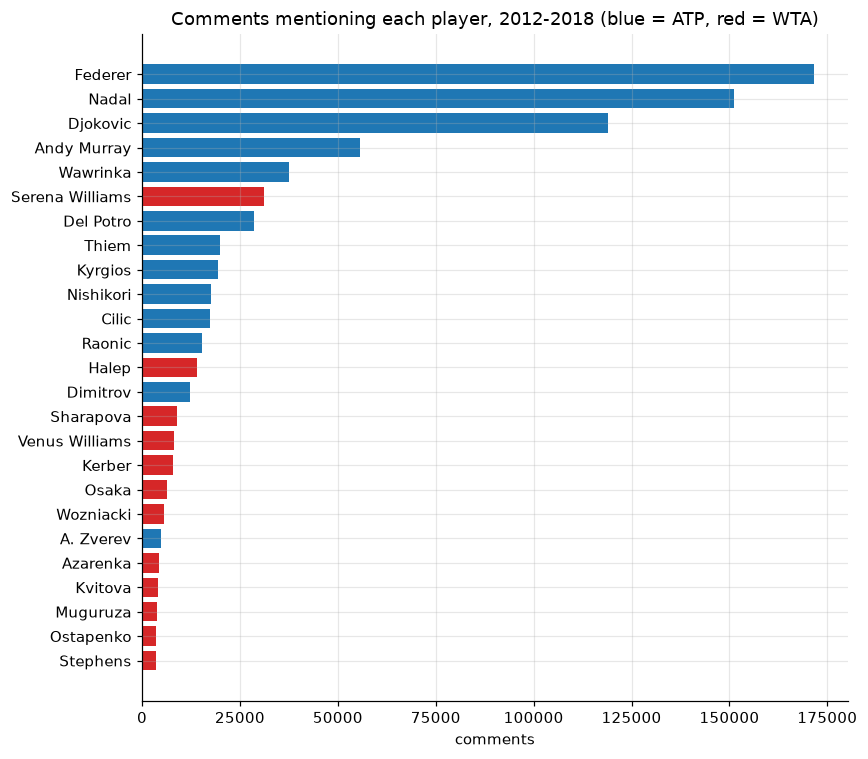

In [6]:
text_plain = plain_lower(F.col("text"))
flags = [F.when(text_plain.rlike(pattern(p)), F.lit(p)) for p in PLAYERS]
mentions = (
    utts.filter(~F.col("is_deleted"))
    .select("id", "year", "month", "date",
            F.explode(F.filter(F.array(*flags), lambda x: x.isNotNull())).alias("player"))
    .cache()
)

player_totals = mentions.groupBy("player").count().toPandas()
player_totals["count"] *= SCALE
player_totals["tour"] = player_totals.player.map(lambda p: PLAYERS[p][0])
player_totals = player_totals.sort_values("count", ascending=False)
save_csv(player_totals, "mentions_by_player")

fig, ax = plt.subplots(figsize=(8, 7))
d = player_totals.sort_values("count")
ax.barh(d.player, d["count"], color=d.tour.map({"ATP": "#1f77b4", "WTA": "#d62728"}))
ax.set_title("Comments mentioning each player, 2012-2018 (blue = ATP, red = WTA)")
ax.set_xlabel("comments")
save_fig(fig, "mentions_by_player")

n_valid = utts.filter(~F.col("is_deleted")).count()
n_mention = mentions.select("id").distinct().count()
summary["share_comments_mentioning_a_player"] = n_mention / n_valid
tour_share = player_totals.groupby("tour")["count"].sum() / player_totals["count"].sum()
summary["mention_share_by_tour"] = tour_share.round(3).to_dict()
print(f"{n_mention / n_valid:.1%} of comments mention at least one listed player")
print("mention share by tour:", summary["mention_share_by_tour"])
player_totals.head(15)

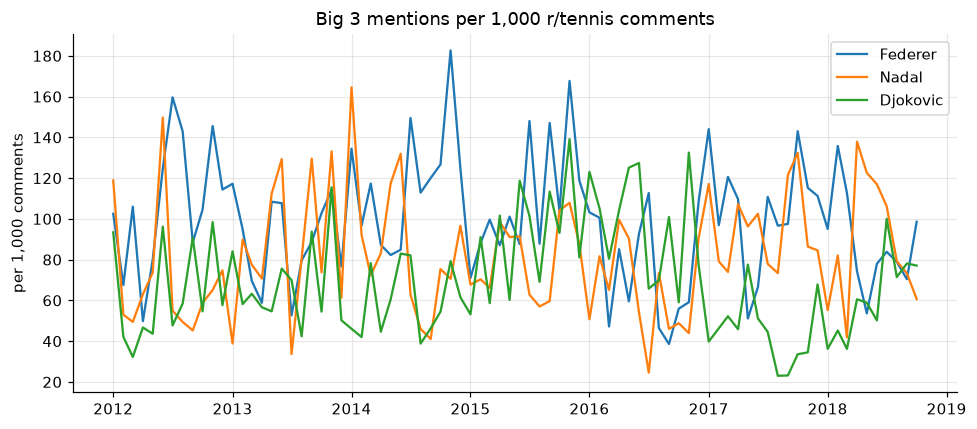

In [7]:
# Big 3 share: comments mentioning the player per 1,000 comments that month.
# Normalising by monthly volume removes the subreddit's growth from the trend.
month_totals = utts.filter(~F.col("is_deleted")).groupBy("year", "month").agg(F.count("*").alias("total"))
big3 = (
    mentions.filter(F.col("player").isin(BIG3))
    .groupBy("year", "month", "player").count()
    .join(month_totals, ["year", "month"])
    .withColumn("per_1000", F.col("count") / F.col("total") * 1000)
    .toPandas()
)
big3["date"] = pd.to_datetime(dict(year=big3.year, month=big3.month, day=1))
big3 = big3.sort_values("date")
save_csv(big3, "big3_monthly_share")

fig, ax = plt.subplots()
for p in BIG3:
    d = big3[big3.player == p]
    ax.plot(d.date, d.per_1000, label=p)
ax.set_title("Big 3 mentions per 1,000 r/tennis comments")
ax.set_ylabel("per 1,000 comments")
ax.legend()
save_fig(fig, "big3_monthly_share")

## 3. Linking match threads to matches

Steps:

1. Classify threads by title: `match` ("Match Thread"), `post-match` ("Post-Match Thread"),
   `result` (any other title that reads like a match or result: "vs", "v", "def", "beats", or a score
   such as "6-4"), or `other`. Match threads only exist for hyped matches, so `result` posts widen
   the sample for question 1 and reduce that selection bias. They are noisier, so a random sample
   is saved for a hand check of link precision.
2. Normalise titles: accents are stripped ("Čilić" becomes "cilic"), player nicknames are replaced by the surname (e.g. "Rafa" becomes "nadal"),
   then the title is split into lowercase word tokens.
3. Join to Sackmann matches (ATP + WTA) where **both** players' surnames appear in the title and the
   thread was posted between 1 day before and 16 days after the tournament start date.
   Sackmann records only the tournament start date, not the match day, so the one-day window in the
   proposal is replaced by the tournament window.
4. If a thread matches several matches, keep the most recent tournament.

In [8]:
def thread_type(title):
    t = F.lower(title)
    return (F.when(t.rlike(r"post[- ]?match"), "post-match")
             .when(t.rlike(r"match ?thread"), "match")
             .when(t.rlike(r"\b(vs?|def|defeats?|beats?)\b|\d-\d"), "result")
             .otherwise("other"))

threads = threads.withColumn("thread_type", thread_type(F.col("title")))
type_counts = (
    threads.groupBy("thread_type")
    .agg(F.count("*").alias("threads"),
         F.expr("percentile_approx(num_comments, 0.5)").alias("median_comments"),
         F.avg("num_comments").alias("mean_comments"))
    .toPandas()
)
save_csv(type_counts, "thread_types")
display(type_counts)
for r in threads.filter(F.col("thread_type") != "other").sample(0.01, seed=1).select("thread_type", "title").limit(40).collect():
    print(f"[{r.thread_type}] {r.title}")

,thread_type,threads,median_comments,mean_comments
0,other,81364,3,15.587717
1,post-match,530,4,75.884906
2,result,11985,1,7.598665
3,match,746,90,432.848525


[result] {{WaTcH}*Youzhny vs Federer Live Streaming Dubai Duty HD TV Link — Sports Live Streaming HD TV Online
[result] WaTcH Djokovic vs Tipsarevic Live Streaming HD TV Sopcast Link For Dubai Duty Free Tennis Championships
[result] [MATCH UPDATES] Andy Murray v Milos Raonic (Monte Carlo Masters quarter final)
[result] Kvitova vs Chirico WTA Stuttgart live Stream
[result] Florin Mergea/Horia Tecau vs Marcus Daniell/Artem Sitak ATP Bucharest 2016 - live 2016
[result] Lucie Safarova vs Karolina Pliskova Porsche Tennis Grand Prix Round 2 - Parking challenges
[result] Marco Cecchinato vs Damir Dzumhur ATP Bucharest Round of 16 - live 2016 tennis update
[result] Monica Puig v Barbora Krejcikova WTA Prague - live 2016 results tennis
[result] Most excited match of the rivalry ? R.Federer vs R.Nadal : French Open 2005 Semi-Final
[result] Alexander Zverev vs Nick Kyrgios Highlights HD 2017
[result] Yonex VCORE Si 105 vs the Yonex EZONE Ai 100 - need some help
[result] What is the worst defeat f

In [9]:
COLS = ["tourney_id", "tourney_name", "surface", "tourney_level", "tourney_date", "match_num",
        "winner_name", "loser_name", "winner_rank", "loser_rank", "score", "best_of", "round", "minutes"]

def load_tour(tour):
    df = spark.read.csv(str(MATCHES / f"{tour}_matches_*.csv"), header=True, inferSchema=False)
    return df.select(*COLS).withColumn("tour", F.lit(tour.upper()))

def last_token(c):
    return F.element_at(F.split(F.trim(plain_lower(c)), r"[^a-z]+"), -1)

matches = (
    load_tour("atp").unionByName(load_tour("wta"))
    .withColumn("tourney_start", F.to_date(F.col("tourney_date").cast("string"), "yyyyMMdd"))
    .filter(F.year("tourney_start").between(YEARS[0] - 1, YEARS[1]))
    .withColumn("winner_rank", F.col("winner_rank").cast("int"))
    .withColumn("loser_rank", F.col("loser_rank").cast("int"))
    .withColumn("w_tok", last_token("winner_name"))
    .withColumn("l_tok", last_token("loser_name"))
    .filter((F.length("w_tok") >= 2) & (F.length("l_tok") >= 2))
    .withColumn("match_key", F.concat_ws("|", "tour", "tourney_id", "match_num"))
    .cache()
)
print("matches:", matches.count())
matches.groupBy("tour").count().show()

matches: 45903


+----+-----+
|tour|count|
+----+-----+
| ATP|23559|
| WTA|22344|
+----+-----+



In [10]:
# Replace nicknames with the surname token used in the match data ("rafa" -> "nadal").
def surname_token(name):
    return name.lower().replace(".", "").split()[-1]

title_norm = plain_lower(F.col("title"))
for p in PLAYERS:
    title_norm = F.regexp_replace(title_norm, pattern(p), surname_token(p))

mt = (
    threads.filter(F.col("thread_type") != "other")
    .withColumn("words", F.split(title_norm, r"[^a-z]+"))
    .withColumn("tokens", F.array_distinct("words"))
    .select("thread_id", "thread_type", "thread_date", "num_comments", "title", "tokens", "words")
)

cand = (
    mt.select("*", F.explode("tokens").alias("tok"))
    .join(matches, F.col("tok") == F.col("w_tok"))
    .filter(F.array_contains("tokens", F.col("l_tok")))
    # Same surname (e.g. S. Williams vs V. Williams): the name must appear twice in the title.
    .filter((F.col("w_tok") != F.col("l_tok"))
            | (F.size(F.filter("words", lambda w: w == F.col("w_tok"))) >= 2))
    .filter(F.col("thread_date").between(F.date_sub("tourney_start", 1), F.date_add("tourney_start", 16)))
    .drop("tok", "tokens", "words")
)
best = Window.partitionBy("thread_id").orderBy(F.desc("tourney_start"), F.desc("match_num"))
linked = cand.withColumn("rn", F.row_number().over(best)).filter("rn = 1").drop("rn").cache()

link_rate = (
    mt.join(linked.select("thread_id", F.lit(1).alias("linked")), "thread_id", "left")
    .groupBy(F.year("thread_date").alias("year"), "thread_type")
    .agg(F.count("*").alias("threads"), F.sum(F.coalesce("linked", F.lit(0))).alias("linked"))
    .withColumn("link_rate", F.round(F.col("linked") / F.col("threads"), 3))
    .orderBy("thread_type", "year")
    .toPandas()
)
save_csv(link_rate, "link_rate")
overall = link_rate.groupby("thread_type")[["threads", "linked"]].sum()
overall["link_rate"] = (overall.linked / overall.threads).round(3)
summary["link_rate"] = overall.link_rate.to_dict()
summary["linked_threads"] = int(overall.linked.sum())
display(overall)
link_rate

,threads,linked,link_rate
thread_type,,,
match,746,683,0.916
post-match,530,347,0.655
result,11985,7736,0.645


,year,thread_type,threads,linked,link_rate
0,2012,match,84,76,0.905
1,2013,match,111,108,0.973
2,2014,match,113,101,0.894
3,2015,match,136,126,0.926
4,2016,match,99,91,0.919
5,2017,match,130,112,0.862
6,2018,match,73,69,0.945
7,2012,post-match,7,3,0.429
8,2013,post-match,18,4,0.222
9,2014,post-match,23,7,0.304


In [11]:
# Unlinked match / post-match threads: read these to improve the title parsing.
# (Most unlinked "result" titles are not about a single match, so they are left out here.)
unlinked = (
    mt.filter(F.col("thread_type") != "result")
    .join(linked.select("thread_id"), "thread_id", "left_anti")
    .select("thread_type", "thread_date", "num_comments", "title")
    .orderBy(F.desc("num_comments"))
    .limit(300)
    .toPandas()
)
save_csv(unlinked, "unlinked_examples")
unlinked.head(30)

,thread_type,thread_date,num_comments,title
0,post-match,2015-07-10,369,Post-match: Men's Semifinals (2015 Wimbledon C...
1,match,2018-07-12,325,"Match Thread: Görges vs Williams (Semi-final, ..."
2,match,2015-06-04,247,Match Thread: Women's Semifinals (2015 French ...
3,post-match,2015-09-12,222,Post-match: Men's Semifinals (2015 US Open)
4,post-match,2016-06-30,114,Bernard Tomic under fire for 'deeply offensive...
5,post-match,2014-11-23,110,Post-match Discussion: France vs Switzerland (...
6,post-match,2017-04-01,107,Federer-Krygios Post Match Thread
7,post-match,2015-11-29,102,Post-match: Belgium vs Great Britain (2015 Dav...
8,post-match,2015-06-05,92,Post-match Discussion: Men's Semifinals (2015 ...
9,post-match,2016-06-14,84,Genie Bouchard's post-match cooldown in Mallorca


In [12]:
# Precision check: 100 random linked result posts. Open the CSV, mark each row correct / wrong
# in a new column, and report the share correct (target: at least 90%).
precision_sample = (
    linked.filter(F.col("thread_type") == "result")
    .orderBy(F.rand(seed=7)).limit(100)
    .select("thread_date", "num_comments", "title", "winner_name", "loser_name", "tourney_name", "round", "tourney_start")
    .toPandas()
)
save_csv(precision_sample, "result_link_precision_sample")
precision_sample.head(20)

,thread_date,num_comments,title,winner_name,loser_name,tourney_name,round,tourney_start
0,2018-07-07,12,Edmund controversial call vs Djokovic Wimbledo...,Novak Djokovic,Kyle Edmund,Wimbledon,R32,2018-07-02
1,2016-07-10,4,Andy Murray vs Milos Raonic Full Highlights 20...,Andy Murray,Milos Raonic,Wimbledon,F,2016-06-27
2,2017-01-05,3,Jo-Wilfried Tsonga vs Dustin Brown 2017 DOHA Q...,Jo-Wilfried Tsonga,Dustin Brown,Doha,R16,2017-01-02
3,2015-11-17,14,Roger Federer vs Novak Djokovic ATP World Tour...,Novak Djokovic,Roger Federer,Tour Finals,F,2015-11-15
4,2018-08-30,0,"US Open 2018: Serena,Venus Set Up Williams vs....",Serena Williams,Venus Williams,US Open,R32,2018-08-27
5,2016-01-19,33,Rafael Nadal vs Fernando Verdasco - Day 2 Aust...,Fernando Verdasco,Rafael Nadal,Australian Open,R128,2016-01-18
6,2017-02-19,1,Ryan Harrison Vs Nikoloz Basilashvili - Memphi...,Ryan Harrison,Nikoloz Basilashvili,Memphis,F,2017-02-13
7,2016-01-28,4,Serena Williams vs Agnieszka Radwanska 2016/01...,Serena Williams,Agnieszka Radwanska,Australian Open,SF,2016-01-18
8,2016-10-08,24,Just a typical Kyrgios vs Monfils point,Nick Kyrgios,Gael Monfils,Tokyo,SF,2016-10-03
9,2017-11-26,11,David Goffin (BEL) Vs Jo-Wilfried Tsonga (FRA)...,David Goffin,Jo-Wilfried Tsonga,Davis Cup WG F: BEL vs FRA,RR,2017-11-24


### First look at question 1: what gets attention?

Comment counts on linked **match** threads by event level, round, upset and Big 3 involvement.
This is descriptive only; the regression comes in milestone 2.

,level,threads,median,mean
0,Grand Slam,378,205.5,699.9
1,Masters / Premier,164,76.0,231.0
2,Other,75,33.0,143.4
3,Tour Finals,66,68.5,124.4


,tour,threads,median,mean
0,ATP,523,98.0,525.9
1,WTA,160,133.0,289.9


,big3,threads,median,mean
0,False,321,98.0,323.1
1,True,362,121.5,601.4


,upset,threads,median,mean
0,False,469,93.0,403.7
1,True,214,162.0,617.2


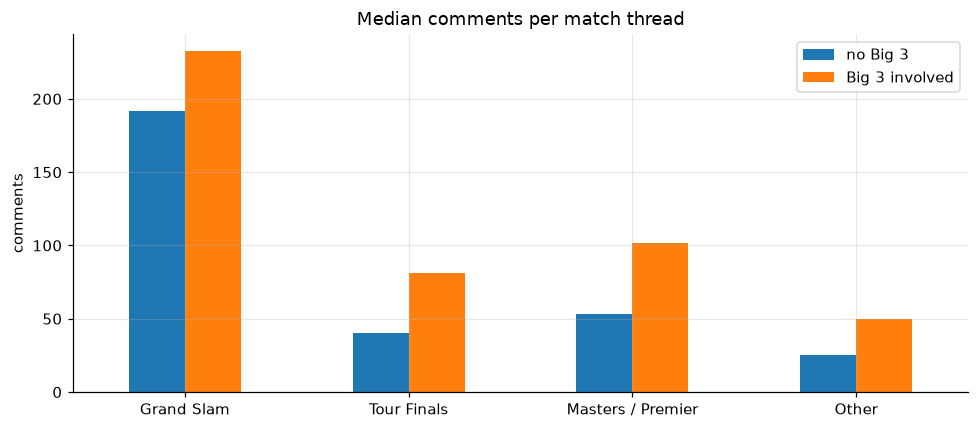

In [13]:
LEVEL = {"G": "Grand Slam", "F": "Tour Finals", "M": "Masters / Premier", "PM": "Masters / Premier",
         "P": "Masters / Premier"}
attn = (
    linked.filter(F.col("thread_type") == "match")
    .withColumn("level", F.coalesce(F.create_map(*[F.lit(x) for kv in LEVEL.items() for x in kv])[F.col("tourney_level")], F.lit("Other")))
    .withColumn("upset", F.col("winner_rank") > F.col("loser_rank"))
    .withColumn("big3", F.col("winner_name").rlike("Federer|Nadal|Djokovic") | F.col("loser_name").rlike("Federer|Nadal|Djokovic"))
    .select("thread_id", "tour", "level", "round", "upset", "big3", "num_comments", "winner_name", "loser_name",
            "tourney_name", "tourney_start", "winner_rank", "loser_rank", "score", "best_of", "minutes", "surface")
    .toPandas()
)
save_csv(attn, "linked_match_threads")

def describe(by):
    return attn.groupby(by)["num_comments"].agg(threads="count", median="median", mean="mean").round(1).reset_index()

for by in ["level", "tour", "big3", "upset"]:
    t = describe(by)
    save_csv(t, f"attention_by_{by}")
    display(t)

fig, ax = plt.subplots()
order = ["Grand Slam", "Tour Finals", "Masters / Premier", "Other"]
d = describe(["level", "big3"]).pivot(index="level", columns="big3", values="median").reindex(order)
d.columns = ["no Big 3", "Big 3 involved"] if len(d.columns) == 2 else d.columns
d.plot.bar(ax=ax, rot=0)
ax.set_title("Median comments per match thread")
ax.set_ylabel("comments")
ax.set_xlabel("")
save_fig(fig, "attention_by_level_big3")

In [14]:
# Per-match attention for milestone 2: one row per match that has at least one linked thread.
match_attention = (
    linked.groupBy("match_key", "tour", "tourney_id", "tourney_name", "tourney_level", "tourney_start", "surface",
                   "round", "best_of", "winner_name", "loser_name", "winner_rank", "loser_rank", "score", "minutes")
    .agg(F.count("*").alias("n_threads"),
         F.sum("num_comments").alias("total_comments"),
         F.max(F.col("thread_type") == "match").alias("has_match_thread"),
         F.sum(F.when(F.col("thread_type") == "match", F.col("num_comments"))).alias("match_thread_comments"))
)
match_attention.write.mode("overwrite").parquet(str(DATA / "parquet" / "match_attention"))
ma = match_attention.groupBy("has_match_thread").agg(F.count("*").alias("matches")).toPandas()
summary["matches_with_a_thread"] = {("with match thread" if r.has_match_thread else "result posts only"): int(r.matches)
                                    for r in ma.itertuples()}
summary["linked_threads_by_type"] = {k: int(v) for k, v in overall.linked.items()}

# Keep the linked dataset for milestone 2 (Spark regression).
linked.write.mode("overwrite").parquet(str(DATA / "parquet" / "linked_threads"))
summary["n_matches"] = matches.count()
with open(OUT_DATA / "eda_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)
print(json.dumps(summary, indent=2, default=str))
spark.stop()

{
  "mode": "full",
  "share_deleted": 0.05424952987801772,
  "share_comments_mentioning_a_player": 0.2923170974121953,
  "mention_share_by_tour": {
    "ATP": 0.869,
    "WTA": 0.131
  },
  "link_rate": {
    "match": 0.916,
    "post-match": 0.655,
    "result": 0.645
  },
  "linked_threads": 8766,
  "matches_with_a_thread": {
    "with match thread": 630,
    "result posts only": 3641
  },
  "linked_threads_by_type": {
    "match": 683,
    "post-match": 347,
    "result": 7736
  },
  "n_matches": 45903
}
